In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys

sys.path.insert(1, '../')
sys.path.insert(1, '../RandomForest')
from MyLovelyFunctions import *
from PrepDataFunctions import *

### Prepare data

In [36]:
df = prep_for_modelling(f"/scratch/hydro4/users/kv25483/FutureFlood/Data/EventDetails_v4/all_catchments_with_topo_and_temporal.pkl", 
                        remove_events_with_zero_flooding = False)
df = df[df['mean_sm_2_before_event'].notna()]
df =df[df['start_year']>1990]

### Subset events by length

In [12]:
short_events = df[df['length_of_active_rain']<10].copy()
med_events = df[(df['length_of_active_rain']>10) & (df['length_of_active_rain'] < 50)].copy()
long_events = df[(df['length_of_active_rain']>50) & (df['length_of_active_rain'] < 80)].copy()

### Create annual summaries for several variables

In [18]:
annual_mean_d50 = (df.groupby("start_year", observed=True)["d50_n"].mean())
annual_mean_gini = (df.groupby("start_year", observed=True)["gini_n"].mean())
annual_mean_ppr = (df.groupby("start_year", observed=True)["peak_position_ratio_n"].mean())
annual_mean_tstd = (df.groupby("start_year", observed=True)["time_based_std_n"].mean())
annual_mean_mqi = (df.groupby("start_year", observed=True)["max_quartile_index_n"].mean())
annual_mean_dr = (df.groupby("start_year", observed=True)["dry_ratio_n"].mean())
annual_mean_length = (df.groupby("start_year", observed=True)["length_of_active_rain"].mean())

annual_mean_cluster_n_cells_t50 = (df.groupby("start_year", observed=True)["cluster_n_cells_t50"].mean())
annual_mean_cluster_n_cells_t60 = (df.groupby("start_year", observed=True)["cluster_n_cells_t60"].mean())
annual_mean_cluster_n_cells_t80 = (df.groupby("start_year", observed=True)["cluster_n_cells_t80"].mean())

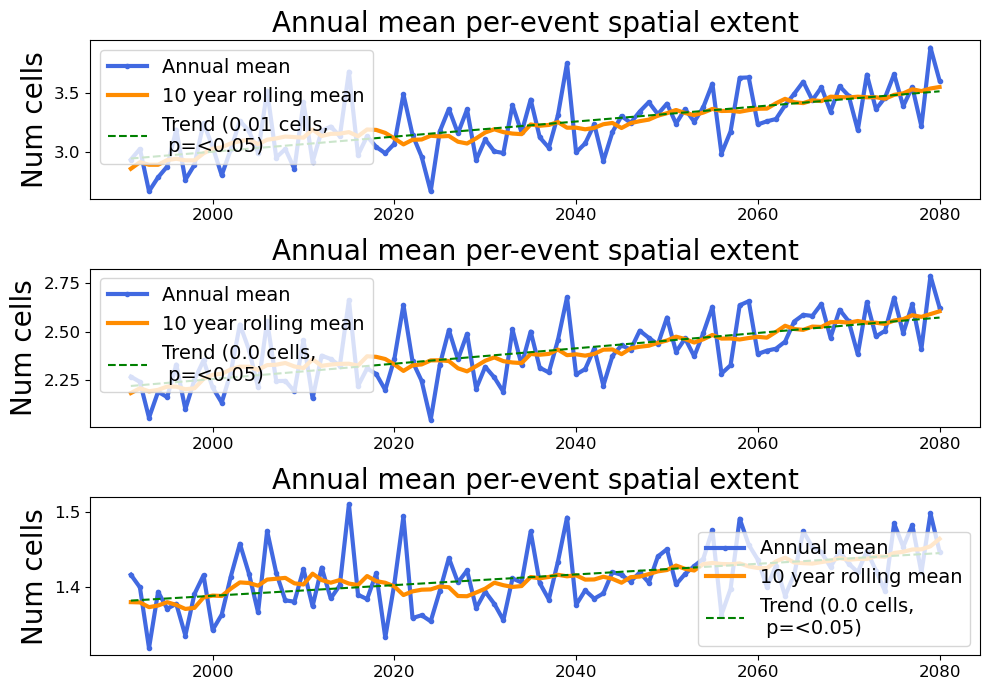

In [19]:
fig, axs = plt.subplots(nrows = 3, figsize=(10, 7), sharex=False)

make_subplot(axs[0], annual_mean_cluster_n_cells_t50, "Num cells", "Annual mean per-event spatial extent", 2, "cells")
make_subplot(axs[1], annual_mean_cluster_n_cells_t60, "Num cells", "Annual mean per-event spatial extent",2, "cells")

make_subplot(axs[2], annual_mean_cluster_n_cells_t80, "Num cells", "Annual mean per-event spatial extent",2, "cells")

plt.tight_layout()

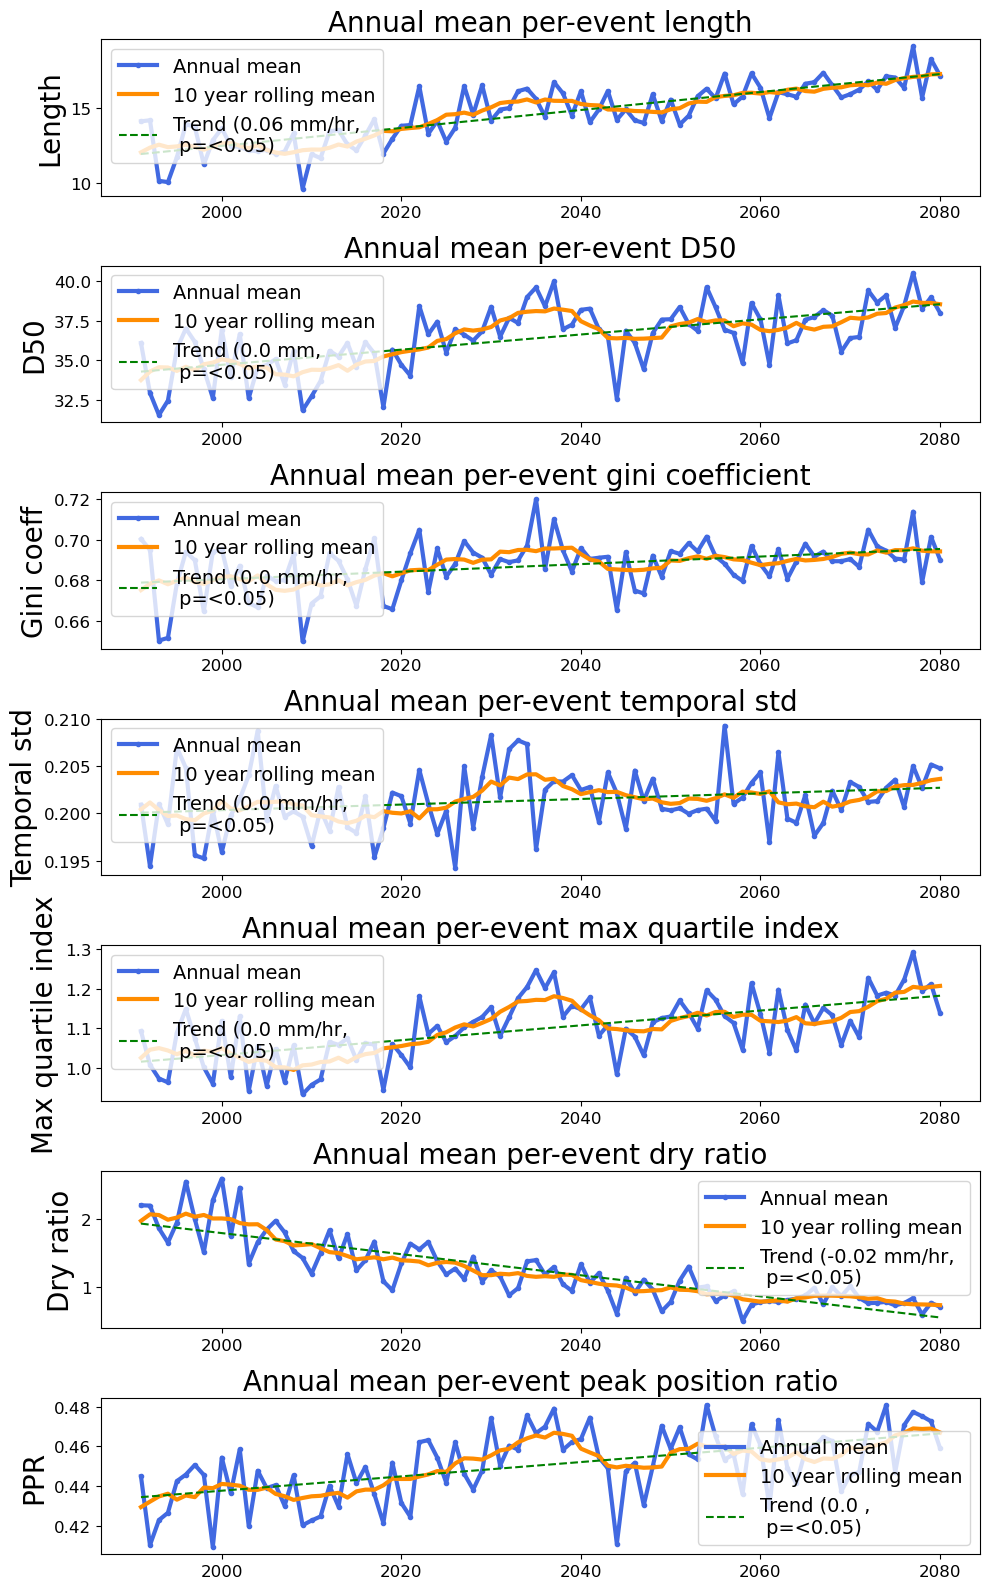

In [20]:
fig, axs = plt.subplots(nrows = 7, figsize=(10, 16), sharex=False)

make_subplot(axs[0], annual_mean_length, "Length", "Annual mean per-event length", 
             2, "mm/hr")
make_subplot(axs[1], annual_mean_d50, "D50", "Annual mean per-event D50",1, "mm")
make_subplot(axs[2], annual_mean_gini, "Gini coeff", "Annual mean per-event gini coefficient", 
             2, "mm/hr")
make_subplot(axs[3], annual_mean_tstd, "Temporal std", "Annual mean per-event temporal std", 
             2, "mm/hr")
make_subplot(axs[4], annual_mean_mqi, "Max quartile index", "Annual mean per-event max quartile index", 
             2, "mm/hr")
make_subplot(axs[5], annual_mean_dr, "Dry ratio", "Annual mean per-event dry ratio", 
             2, "mm/hr")
make_subplot(axs[6], annual_mean_ppr, "PPR", "Annual mean per-event peak position ratio",1, "")

plt.tight_layout()

In [41]:
df = df[df['length_of_active_rain'] < 80]
early_events = df[df['start_year']>2020].copy()
med_events = df[(df['start_year']>2020) & (df['start_year'] < 2050)].copy()
late_events = df[(df['start_year']>2050)].copy()

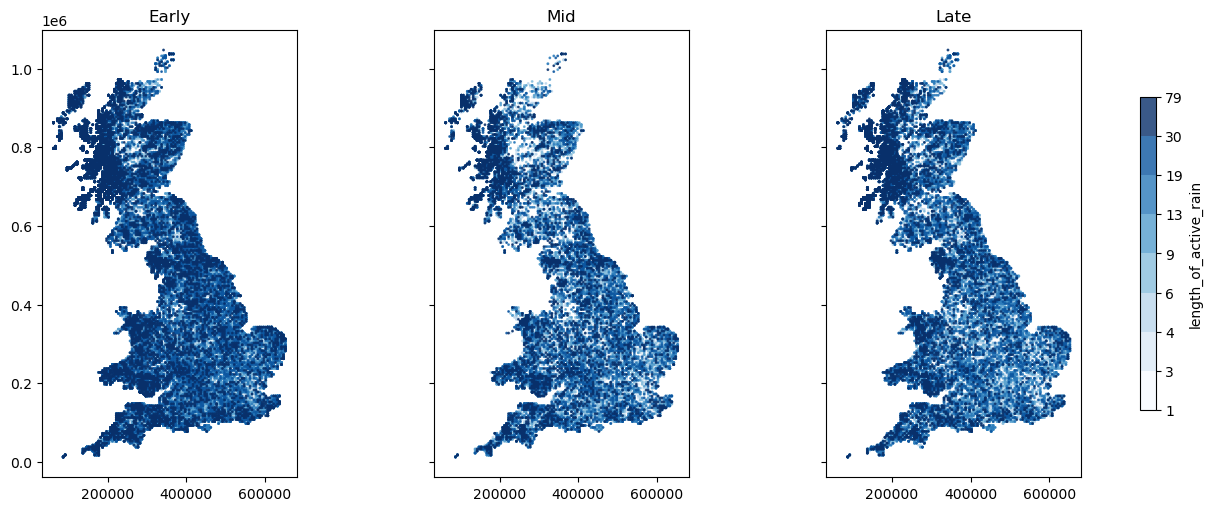

In [47]:
import matplotlib.colors as mcolors

col = 'length_of_active_rain'
dfs = [early_events, med_events, late_events]
titles = ["Early", "Mid", "Late"]
pooled = pd.concat([d[col] for d in dfs])

n_colours = 8
edges = np.unique(np.quantile(pooled, np.linspace(0, 1, n_colours + 1)))   # same edges for all panels
cmap = plt.get_cmap("Blues", len(edges) - 1)                              # or "YlGnBu", "magma_r"
norm = mcolors.BoundaryNorm(edges, cmap.N)

fig, axs = plt.subplots(figsize=(13, 5), ncols=3, sharex=True, sharey=True, constrained_layout=True)
for ax, df, t in zip(axs, dfs, titles):
    df = df.sort_values(col)                    # high values drawn last, so they aren't buried
    sc = ax.scatter(df['x_coord'], df['y_coord'], c=df[col], cmap=cmap, norm=norm, s=1, alpha=0.8)
    ax.set_title(t); ax.set_aspect("equal")

cb = fig.colorbar(sc, ax=axs, shrink=0.7, label=col)
cb.set_ticks(edges)
cb.ax.set_yticklabels([f"{e:.3g}" for e in edges])
plt.show()

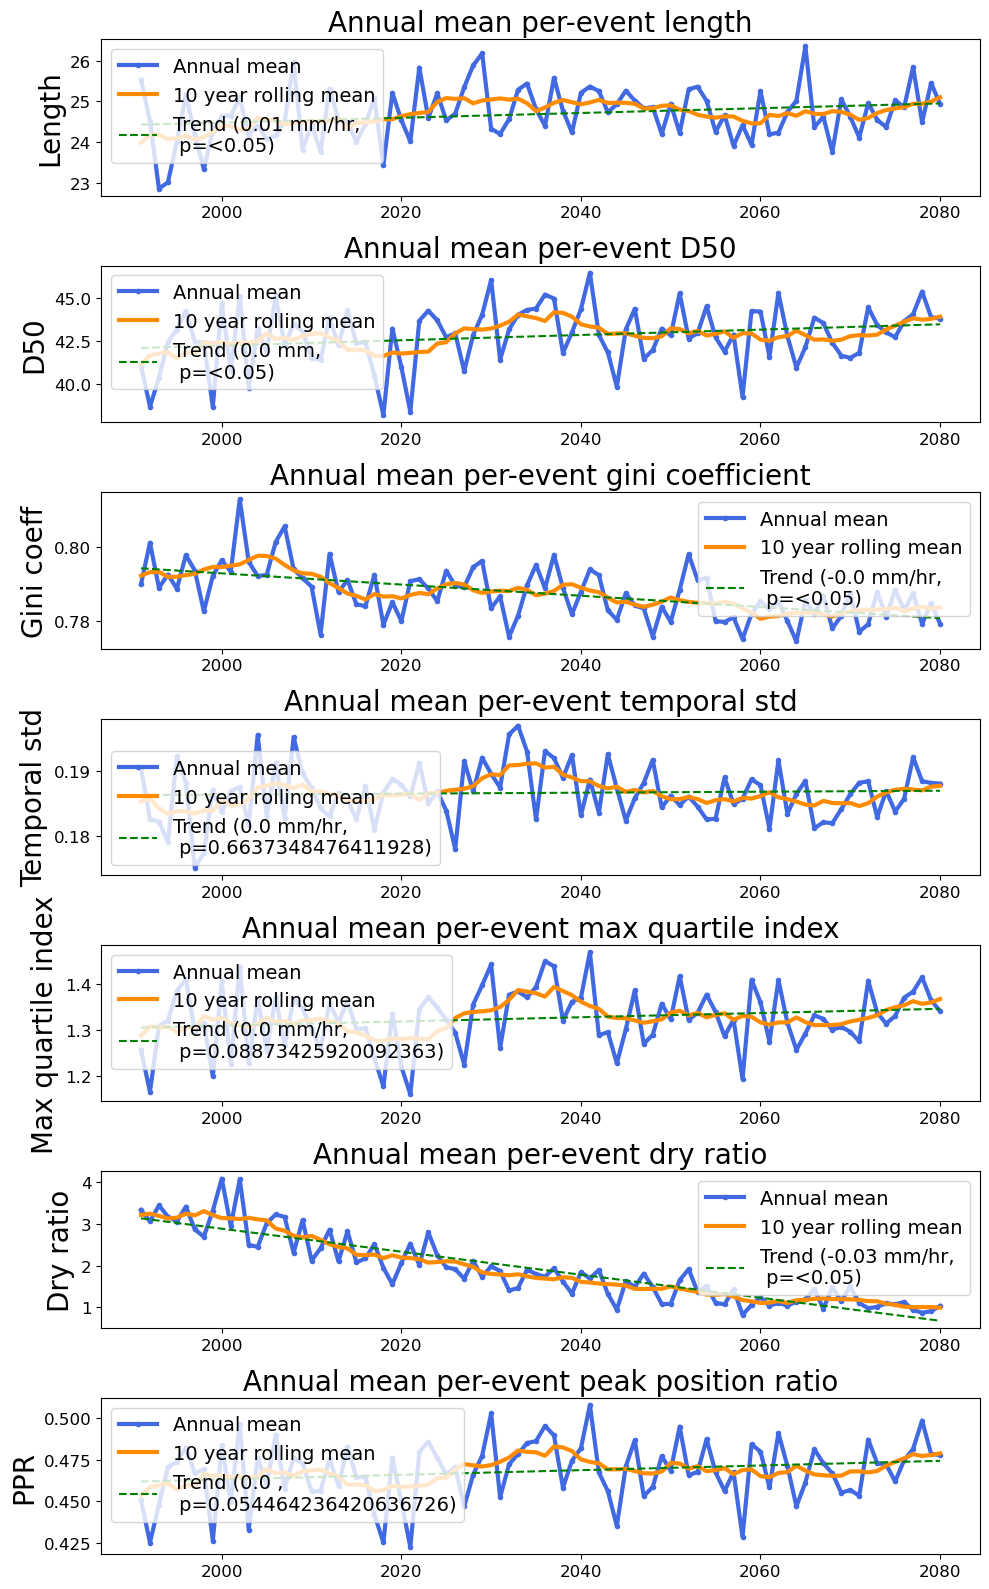

In [9]:
fig, axs = plt.subplots(nrows = 7, figsize=(10, 16), sharex=False)

make_subplot(axs[0], annual_mean_length, "Length", "Annual mean per-event length", 
             2, "mm/hr")
make_subplot(axs[1], annual_mean_d50, "D50", "Annual mean per-event D50",1, "mm")
make_subplot(axs[2], annual_mean_gini, "Gini coeff", "Annual mean per-event gini coefficient", 
             2, "mm/hr")
make_subplot(axs[3], annual_mean_tstd, "Temporal std", "Annual mean per-event temporal std", 
             2, "mm/hr")
make_subplot(axs[4], annual_mean_mqi, "Max quartile index", "Annual mean per-event max quartile index", 
             2, "mm/hr")
make_subplot(axs[5], annual_mean_dr, "Dry ratio", "Annual mean per-event dry ratio", 
             2, "mm/hr")
make_subplot(axs[6], annual_mean_ppr, "PPR", "Annual mean per-event peak position ratio",1, "")

plt.tight_layout()